# Travel eSIM prices in 196 countries: a first look

How much the same 10 GB / 30 days pack costs in different destinations, by part of the world, and where a regional plan is cheaper than the country plan. Final retail prices of one store (Letsim) in Russian roubles as of 23 Nov 2026 — not market averages.

Archived release: [doi:10.5281/zenodo.24510832](https://doi.org/10.5281/zenodo.24510832). Page with findings (in Russian): https://letsim.ru/issledovaniya/stoimost-interneta-v-poezdke

*Disclosure: Letsim is a commercial travel eSIM provider that sells these plans.*

In [1]:
import glob
import pandas as pd
import matplotlib.pyplot as plt

def find(name):
    """Path to a dataset file on Kaggle (/kaggle/input/...) or in the current folder."""
    hits = glob.glob(f'/kaggle/input/**/{name}', recursive=True) or glob.glob(name)
    return hits[0]

read = lambda name: pd.read_csv(find(name), sep=';', encoding='utf-8-sig')

df = read('data.csv')
print(df.shape)
df.head()

(196, 12)


,country_code,country_ru,world_region,min_price_rub,price_1gb_7d_rub,price_10gb_30d_rub,price_per_gb_10gb_rub,unlimited_lite_7d_rub,cheaper_regional_plan,cheaper_regional_10gb_30d_rub,plans_count,page_url
0,AU,Австралия,Океания,190,240,1140.0,114.0,1240.0,NaN,NaN,45,https://letsim.ru/esim/avstraliya
1,AT,Австрия,Европа,190,190,1040.0,104.0,1040.0,NaN,NaN,44,https://letsim.ru/esim/avstriya
2,AZ,Азербайджан,СНГ и Кавказ,290,490,2790.0,279.0,2290.0,NaN,NaN,44,https://letsim.ru/esim/azerbaidzhan
3,AX,Аландские острова,Европа,390,390,2140.0,214.0,1940.0,NaN,NaN,33,https://letsim.ru/esim/alandskie-ostrova
4,AL,Албания,Европа,190,290,1540.0,154.0,1190.0,NaN,NaN,44,https://letsim.ru/esim/albaniya


## 10 GB for 30 days: median, cheapest and most expensive

In [2]:
p = df.dropna(subset=['price_10gb_30d_rub'])
print(f"Destinations with the pack: {len(p)}, median: {p.price_10gb_30d_rub.median():,.0f} RUB")
cols = ['country_code', 'country_ru', 'world_region', 'price_10gb_30d_rub']
lo, hi = p.nsmallest(5, 'price_10gb_30d_rub')[cols], p.nlargest(5, 'price_10gb_30d_rub')[cols]
print(f"Spread: {hi.price_10gb_30d_rub.iloc[0] / lo.price_10gb_30d_rub.iloc[0]:.0f}x")
display(lo)
display(hi)

Destinations with the pack: 192, median: 2,465 RUB
Spread: 49x


,country_code,country_ru,world_region,price_10gb_30d_rub
167,TR,Турция,Ближний Восток,590.0
72,ES,Испания,Европа,740.0
83,CY,Кипр,Европа,740.0
48,DE,Германия,Европа,840.0
160,TH,Таиланд,Юго-Восточная Азия,840.0


,country_code,country_ru,world_region,price_10gb_30d_rub
123,NC,Новая Каледония,Океания,28690.0
113,MC,Монако,Европа,23090.0
163,TG,Того,Африка,20790.0
74,YE,Йемен,Ближний Восток,19140.0
177,PF,Французская Полинезия,Океания,18740.0


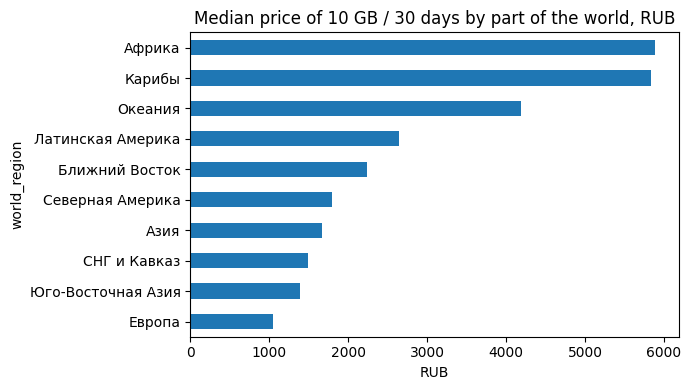

,median,count
world_region,,
Европа,1040.0,48
Юго-Восточная Азия,1390.0,9
СНГ и Кавказ,1490.0,9
Азия,1665.0,14
Северная Америка,1790.0,2
Ближний Восток,2240.0,11
Латинская Америка,2640.0,20
Океания,4190.0,11
Карибы,5840.0,25


In [3]:
by_region = p.groupby('world_region')['price_10gb_30d_rub'].agg(['median', 'count']).sort_values('median')
by_region['median'].plot.barh(figsize=(7, 4), title='Median price of 10 GB / 30 days by part of the world, RUB')
plt.xlabel('RUB')
plt.tight_layout()
plt.show()
by_region

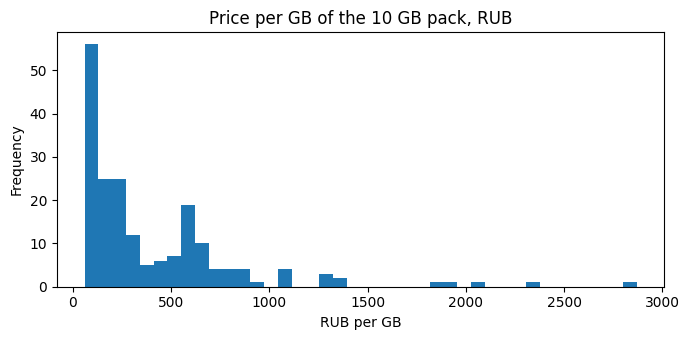

In [4]:
p['price_per_gb_10gb_rub'].plot.hist(bins=40, figsize=(7, 3.5), title='Price per GB of the 10 GB pack, RUB')
plt.xlabel('RUB per GB')
plt.tight_layout()
plt.show()

## Where a regional plan is cheaper than the country plan

In [5]:
reg = df.dropna(subset=['cheaper_regional_plan']).copy()
reg['saving_rub'] = reg.price_10gb_30d_rub - reg.cheaper_regional_10gb_30d_rub
print(f'Destinations: {len(reg)}')
reg[['country_code', 'country_ru', 'price_10gb_30d_rub', 'cheaper_regional_plan', 'cheaper_regional_10gb_30d_rub', 'saving_rub']].sort_values('saving_rub', ascending=False)

Destinations: 17


,country_code,country_ru,price_10gb_30d_rub,cheaper_regional_plan,cheaper_regional_10gb_30d_rub,saving_rub
188,SZ,Эсватини,8440.0,Весь мир,6140.0,2300.0
27,BW,Ботсвана,7690.0,Весь мир,6140.0,1550.0
79,CM,Камерун,7390.0,Весь мир,6140.0,1250.0
31,BF,Буркина-Фасо,7290.0,Весь мир,6140.0,1150.0
149,VC,Сент-Винсент и Гренадины,8190.0,Карибы и Латинская Америка,7240.0,950.0
32,BT,Бутан,3490.0,Южная Азия,2690.0,800.0
136,CG,Республика Конго,6840.0,Весь мир,6140.0,700.0
92,LA,Лаос,2140.0,Юго-Восточная Азия,1490.0,650.0
39,GA,Габон,5990.0,Африка,5590.0,400.0
180,TD,Чад,5990.0,Африка,5590.0,400.0


## License and citation

CC BY 4.0. Cite as: *Letsim (letsim.ru). How much mobile internet costs while travelling: travel eSIM prices in 196 countries. Prices as of 23 November 2026. doi:10.5281/zenodo.24510832.*